# Задача №7: Расчет ТСО, выбор инфраструктурной стратегии и точка безубыточности

## Цель работы
Рассчитать совокупную стоимость владения (ТСО) для трех вариантов ИТ-инфраструктуры государственного информационного портала на горизонте 5 лет и выбрать экономически наиболее эффективную стратегию. Дополнительно определить, когда наступает точка безубыточности между On-premise и Cloud при продлении горизонта за пределы 5 лет.

## Исходные данные

### Вариант 1: On-premise ЦОД
| Параметр | Значение |
|---|---|
| Приобретение оборудования и ПО (разово) | 85 млн руб. |
| Настройка и интеграция (разово) | 12 млн руб. |
| Ежегодная эксплуатация (электричество, охлаждение) | 4.5 млн руб. |
| Персонал (администрирование, поддержка) | 9.0 млн руб./год |
| Обновление ПО (ежегодно) | 2.5 млн руб. |
| Обучение (разово, 1-й год) | 1.5 млн руб. |
| Простои и восстановление (в среднем) | 3.0 млн руб./год |
| Модернизация (через 3 года) | 8.0 млн руб. |

### Вариант 2: Облачный провайдер (IaaS + PaaS)
| Параметр | Значение |
|---|---|
| Настройка и миграция (разово) | 5.0 млн руб. |
| Облачные услуги (ежегодно) | 16.0 млн руб. (с ростом 5% в год) |
| Персонал (администрирование) | 4.0 млн руб./год |
| Поддержка провайдера | 2.5 млн руб./год |
| Обучение (разово, 1-й год) | 2.0 млн руб. |

### Вариант 3: Гибридная стратегия
| Параметр | Значение |
|---|---|
| Приобретение оборудования (разово) | 35.0 млн руб. |
| Настройка и интеграция (разово) | 8.0 млн руб. |
| Облачные услуги (ежегодно) | 8.0 млн руб. |
| Эксплуатация (ежегодно) | 3.0 млн руб. |
| Персонал (ежегодно) | 6.0 млн руб. |
| Поддержка (ежегодно) | 2.0 млн руб. |
| Модернизация (через 3 года) | 4.0 млн руб. |

### Дополнительные параметры
| Параметр | Значение |
|---|---|
| Ставка дисконтирования | 12% |
| Горизонт планирования | 5 лет |
| Налог на имущество (On-premise) | 2.2% от остаточной стоимости |
| Амортизация (On-premise) | Линейная, 5 лет |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Настройка стиля графиков
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

# --- Ввод исходных данных ---
r = 0.12
horizon = 5

print("Исходные данные загружены.")

Исходные данные загружены.


## Часть 1. Расчет ТСО для каждого варианта

Рассчитаем ежегодные денежные потоки (затраты) для каждого варианта. 
**ТСО** рассчитывается как сумма дисконтированных затрат:
$$TCO = \sum_{t=0}^{T} \frac{CAPEX_t + OPEX_t + \text{Скрытые затраты}_t}{(1+r)^t}$$

Где:
- $t$ — год (0-5).
- $CAPEX$ — капитальные затраты.
- $OPEX$ — операционные затраты.
- $r$ — ставка дисконтирования (12%).

In [2]:
# Создаем словарь для хранения денежных потоков
cash_flows = {}

# --- Вариант 1: On-premise ---
# Для налога на имущество используем линейную амортизацию
equip_cost_onprem = 85.0
depreciation = equip_cost_onprem / horizon

# Рассчитаем остаточную стоимость и налог на имущество для каждого года
# Налог считается от среднегодовой стоимости (начало + конец) / 2
onprem_cf = [0] * (horizon + 1)
onprem_cf[0] = 85.0 + 12.0 + 1.5  # Оборудование + Интеграция + Обучение

# Переменные для расчета налога
residual_value = equip_cost_onprem
tax_rate = 0.022

for year in range(1, horizon + 1):
    # Текущие затраты
    opex = 4.5 + 9.0 + 2.5 + 3.0  # Эксплуатация + Персонал + ПО + Простои
    
    # Налог на имущество (от среднегодовой стоимости)
    # В год модернизации (3-й) стоимость увеличивается
    modern_cost = 8.0 if year == 3 else 0.0
    
    # Среднегодовая стоимость = (Начало года + Конец года) / 2
    begin_value = residual_value
    end_value = begin_value - depreciation + modern_cost
    avg_value = (begin_value + end_value) / 2
    property_tax = avg_value * tax_rate
    
    # Обновляем остаточную стоимость для следующего года
    residual_value = end_value
    
    onprem_cf[year] = opex + modern_cost + property_tax

cash_flows['On-premise'] = onprem_cf

# --- Вариант 2: Облако ---
cloud_cf = [0] * (horizon + 1)
cloud_cf[0] = 5.0 + 2.0  # Настройка + Обучение

for year in range(1, horizon + 1):
    # Облачные услуги с ростом 5% в год
    cloud_services = 16.0 * (1.05 ** (year - 1))
    opex = cloud_services + 4.0 + 2.5  # Услуги + Персонал + Поддержка
    cloud_cf[year] = opex

cash_flows['Cloud'] = cloud_cf

# --- Вариант 3: Гибрид ---
hybrid_cf = [0] * (horizon + 1)
hybrid_cf[0] = 35.0 + 8.0  # Оборудование + Интеграция

# Для гибрида также считаем налог на имущество (упрощенно, как для On-premise)
equip_cost_hybrid = 35.0
depreciation_hybrid = equip_cost_hybrid / horizon
residual_value_hybrid = equip_cost_hybrid

for year in range(1, horizon + 1):
    opex = 8.0 + 3.0 + 6.0 + 2.0  # Облако + Эксплуатация + Персонал + Поддержка
    
    modern_cost = 4.0 if year == 3 else 0.0
    
    begin_value = residual_value_hybrid
    end_value = begin_value - depreciation_hybrid + modern_cost
    avg_value = (begin_value + end_value) / 2
    property_tax = avg_value * tax_rate
    
    residual_value_hybrid = end_value
    
    hybrid_cf[year] = opex + modern_cost + property_tax

cash_flows['Hybrid'] = hybrid_cf

# Вывод денежных потоков в таблице
cf_df = pd.DataFrame(cash_flows, index=[f'Year {i}' for i in range(horizon + 1)])
cf_df = cf_df.transpose()
print("Ежегодные затраты (млн руб.):")
display(cf_df.round(2))

Ежегодные затраты (млн руб.):


,Year 0,Year 1,Year 2,Year 3,Year 4,Year 5
On-premise,98.5,20.68,20.31,28.02,19.74,19.36
Cloud,7.0,22.50,23.30,24.14,25.02,25.95
Hybrid,43.0,19.69,19.54,23.43,19.32,19.16


## Часть 2.1. Дисконтирование и расчет ТСО

Теперь продисконтируем денежные потоки и найдем суммарный ТСО для каждого варианта.

**Формула:**
$$PV_t = \frac{CF_t}{(1+r)^t}$$
$$TCO = \sum_{t=0}^{5} PV_t$$

Где $r = 12\%$.

In [3]:
# Словарь для хранения дисконтированных потоков и ТСО
discounted_cf = {}
tco_results = {}

for variant, cf in cash_flows.items():
    discounted = []
    total_tco = 0
    for t, value in enumerate(cf):
        pv = value / ((1 + r) ** t)
        discounted.append(pv)
        total_tco += pv
    discounted_cf[variant] = discounted
    tco_results[variant] = total_tco

# Вывод результатов
print("Суммарный ТСО за 5 лет (млн руб.):")
for variant, tco in sorted(tco_results.items(), key=lambda x: x[1]):
    print(f"{variant}: {tco:.2f}")

# Определение лучшего варианта
best_variant = min(tco_results, key=tco_results.get)
print(f"\nНаименьший ТСО у варианта: {best_variant}")

# Таблица дисконтированных потоков
dcf_df = pd.DataFrame(discounted_cf, index=[f'Year {i}' for i in range(horizon + 1)]).transpose()
print("\nДисконтированные затраты (млн руб.):")
display(dcf_df.round(2))

Суммарный ТСО за 5 лет (млн руб.):
Cloud: 93.47
Hybrid: 115.99
On-premise: 176.63

Наименьший ТСО у варианта: Cloud

Дисконтированные затраты (млн руб.):


,Year 0,Year 1,Year 2,Year 3,Year 4,Year 5
On-premise,98.5,18.47,16.19,19.95,12.54,10.99
Cloud,7.0,20.09,18.57,17.18,15.90,14.72
Hybrid,43.0,17.58,15.58,16.68,12.28,10.87


## Часть 2.2. Сравнение накопленных ТСО за 5 лет

Сначала рассчитаем накопленные дисконтированные затраты всех трёх вариантов по годам, затем построим график. Это общее сравнение ТСО за горизонт 5 лет, а не поиск точки безубыточности: на графике видно, что Cloud дешевле всех на всём горизонте. Точка безубыточности считается отдельно для пары On-premise и Cloud в частях 2.3–2.4.


In [4]:
# Накопленные дисконтированные затраты по годам
cumulative_df = pd.DataFrame(
    {variant: np.cumsum(dcf) for variant, dcf in discounted_cf.items()},
    index=[f'Year {i}' for i in range(horizon + 1)]
).transpose()

print("Накопленные дисконтированные затраты (млн руб.):")
display(cumulative_df.round(2))


Накопленные дисконтированные затраты (млн руб.):


,Year 0,Year 1,Year 2,Year 3,Year 4,Year 5
On-premise,98.5,116.97,133.16,153.10,165.65,176.63
Cloud,7.0,27.09,45.66,62.85,78.75,93.47
Hybrid,43.0,60.58,76.16,92.84,105.11,115.99


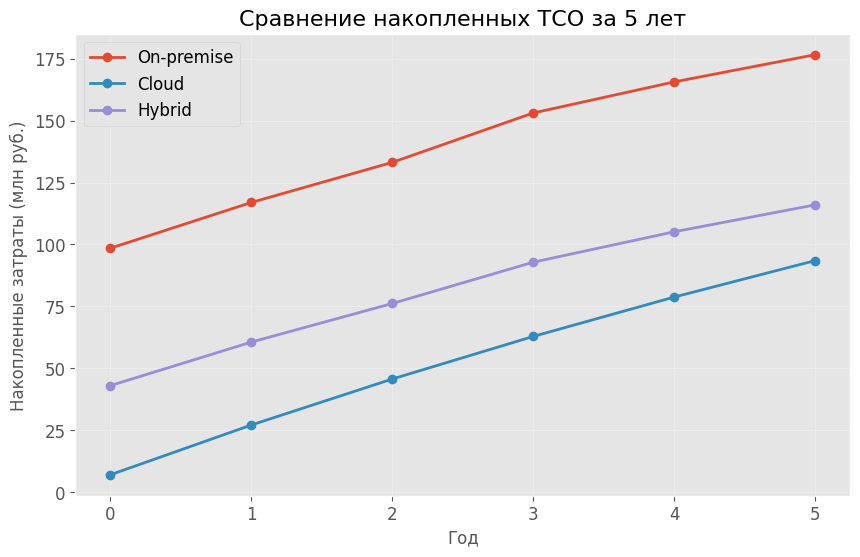

In [5]:
# Построение графика накопленных дисконтированных затрат
plt.figure(figsize=(10, 6))

for variant in cumulative_df.index:
    plt.plot(range(horizon + 1), cumulative_df.loc[variant],
             marker='o', label=variant, linewidth=2)

plt.title('Сравнение накопленных ТСО за 5 лет', fontsize=16)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Накопленные затраты (млн руб.)', fontsize=12)
plt.xticks(range(horizon + 1))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## Часть 2.3. Расчёт точки безубыточности On-premise и Cloud в пределах 5 лет

Точка безубыточности — год, в котором накопленные дисконтированные затраты On-premise и Cloud сравниваются.

**Формула:**
$$\Delta_t = \sum_{i=0}^{t} \frac{CF_i^{On}}{(1+r)^i} - \sum_{i=0}^{t} \frac{CF_i^{Cloud}}{(1+r)^i}$$

Точка безубыточности — это \(t^*\), при котором \(\Delta_{t^*}=0\).

За 5 лет Cloud дешевле: 93,47 против 176,63 млн руб. Разрыв положителен и не меняет знак, поэтому точка безубыточности не достигается. Продлим горизонт в части 2.4. График из 2.2 показывает общее сравнение трёх вариантов; здесь рассчитывается разрыв именно для пары On-premise и Cloud.


In [6]:
# Накопленные дисконтированные затраты за 5 лет
cum_onprem = np.cumsum(discounted_cf['On-premise'])
cum_cloud = np.cumsum(discounted_cf['Cloud'])

be_5 = pd.DataFrame({
    'Год': range(horizon + 1),
    'On-premise, накопленные PV': cum_onprem,
    'Cloud, накопленные PV': cum_cloud,
    'Разрыв (On-premise − Cloud)': cum_onprem - cum_cloud,
}).set_index('Год')

print("Накопленные дисконтированные затраты за 5 лет (млн руб.):")
display(be_5.round(2))

gap_5 = be_5['Разрыв (On-premise − Cloud)'].iloc[-1]
print(f"Разрыв в конце 5-го года: {gap_5:.2f} млн руб.")
print("Знак разрыва не меняется → в пределах 5 лет точка безубыточности не достигается, Cloud дешевле.")


Накопленные дисконтированные затраты за 5 лет (млн руб.):


,"On-premise, накопленные PV","Cloud, накопленные PV",Разрыв (On-premise − Cloud)
Год,,,
0,98.50,7.00,91.50
1,116.97,27.09,89.88
2,133.16,45.66,87.49
3,153.10,62.85,90.26
4,165.65,78.75,86.90
5,176.63,93.47,83.16


Разрыв в конце 5-го года: 83.16 млн руб.
Знак разрыва не меняется → в пределах 5 лет точка безубыточности не достигается, Cloud дешевле.


## Часть 2.4. Точка безубыточности On-premise и Cloud за пределами 5 лет

По условию задачи точка безубыточности считается между **On-premise и Cloud**.
### За счёт чего она достигается

Cloud выигрывает на старте за счёт низких начальных затрат: 7,0 против 98,5 млн руб. Разрыв начальных затрат:

$$\Delta C_0 = 98{,}5 - 7{,}0 = 91{,}5 \text{ млн руб.}$$

Дальше On-premise отыгрывает этот разрыв за счёт более низких ежегодных затрат. Накопленный дисконтированный разрыв:

$$\Delta_t^{PV} = 91{,}5 - \sum_{i=1}^{t}\frac{OPEX_{cloud,i} - OPEX_{onprem,i}}{(1+r)^i}$$

Точка безубыточности наступает, когда дисконтированная экономия OPEX покроет 91,5 млн руб. В 3-м году разрыв временно увеличивается из-за модернизации On-premise на 8,0 млн руб.

К 5-му году On-premise покрывает только **8,34 млн руб. PV** из 91,5 млн, остаток — **83,16 млн руб.** После 5-го года затраты On-premise стабилизируются на 19,0 млн руб., а Cloud продолжает дорожать на 5%: экономия составляет около 7,9 млн руб. в 6-м году и растёт, но будущие суммы дисконтируются. Поэтому остаток закрывается только к **34-му году**.

**Допущения для продления:**
- после 5-го года оборудование On-premise полностью самортизировано, налог на имущество равен нулю;
- ежегодные затраты On-premise после 5-го года — 19,0 млн руб.;
- облачные услуги продолжают дорожать на 5% в год;
- замена оборудования и новые модернизации не учитываются.


In [7]:
# Продлеваем денежные потоки за пределы горизонта
def extend_cash_flows(cf, variant, years=60):
    '''Продлевает поток затрат с учётом допущений части 2.4.'''
    result = list(cf)
    for t in range(horizon + 1, years + 1):
        if variant == 'On-premise':
            result.append(4.5 + 9.0 + 2.5 + 3.0)  # налог = 0 после амортизации
        else:
            result.append(16.0 * (1.05 ** (t - 1)) + 4.0 + 2.5)
    return result


def find_breakeven(cf_a, cf_b, rate):
    '''Год, в котором накопленные дисконтированные затраты A и B сравниваются.'''
    cum_a = cum_b = 0
    gaps = []
    for t, (a, b) in enumerate(zip(cf_a, cf_b)):
        a = a / (1 + rate) ** t
        b = b / (1 + rate) ** t
        cum_a += a
        cum_b += b
        gaps.append(cum_a - cum_b)

    for t in range(1, len(gaps)):
        if gaps[t - 1] * gaps[t] <= 0 and gaps[t - 1] != 0:
            year = t - 1 + abs(gaps[t - 1]) / (abs(gaps[t - 1]) + abs(gaps[t]))
            return year, gaps
    return None, gaps


onprem_long = extend_cash_flows(cash_flows['On-premise'], 'On-premise')
cloud_long = extend_cash_flows(cash_flows['Cloud'], 'Cloud')

be_pv, _ = find_breakeven(onprem_long, cloud_long, rate=r)
print(f"Точка безубыточности On-premise vs Cloud (дисконтирование 12%): {be_pv:.1f}-й год")


Точка безубыточности On-premise vs Cloud (дисконтирование 12%): 34.0-й год


In [8]:
# Покрытие начального разрыва дисконтированной экономией OPEX
capex_gap = onprem_long[0] - cloud_long[0]
print(f"Начальный разрыв On-premise − Cloud: {capex_gap:.2f} млн руб.")

rows = []
for t in [0, 5, 10, 15, 20, 25, 30, 33, 34]:
    pv_savings = sum((cloud_long[i] - onprem_long[i]) / (1 + r) ** i
                     for i in range(1, t + 1))
    rows.append({
        'Год': t,
        'Накопленная экономия OPEX (PV)': pv_savings,
        'Остаток начального разрыва (PV)': capex_gap - pv_savings,
    })

bridge = pd.DataFrame(rows).set_index('Год')
print("\nПокрытие разрыва дисконтированной экономией OPEX (млн руб.):")
display(bridge.round(2))

savings_5 = bridge.loc[5, 'Накопленная экономия OPEX (PV)']
print(f"К 5-му году покрыто {savings_5:.2f} млн руб. PV из {capex_gap:.2f} млн руб.")


Начальный разрыв On-premise − Cloud: 91.50 млн руб.

Покрытие разрыва дисконтированной экономией OPEX (млн руб.):


,Накопленная экономия OPEX (PV),Остаток начального разрыва (PV)
Год,,
0,0.00,91.50
5,8.34,83.16
10,28.42,63.08
15,46.98,44.52
20,62.69,28.81
25,75.36,16.14
30,85.27,6.23
33,90.07,1.43
34,91.50,-0.00


К 5-му году покрыто 8.34 млн руб. PV из 91.50 млн руб.


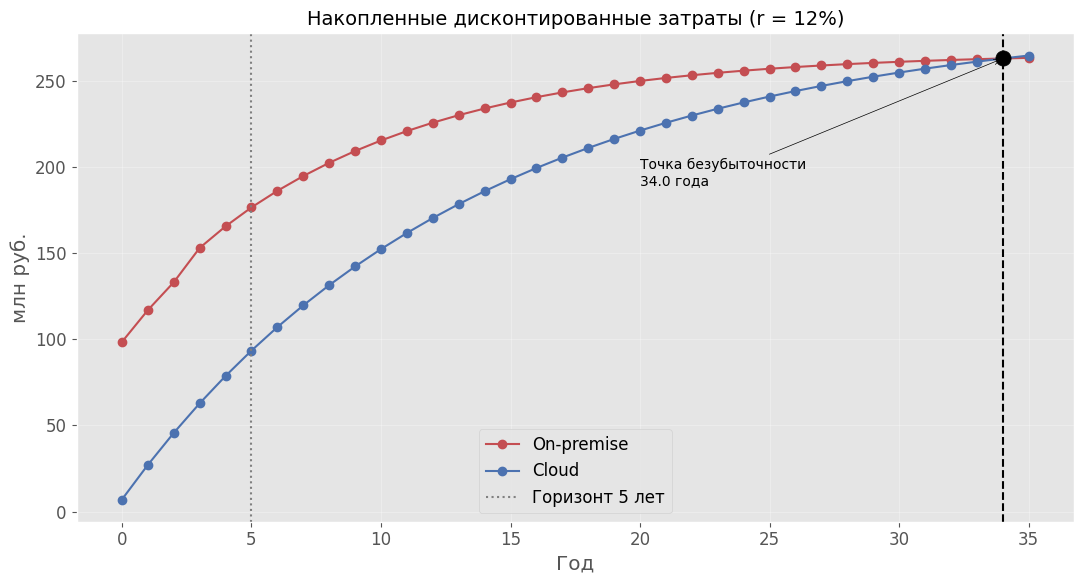

In [9]:
# Накопленные дисконтированные затраты до точки безубыточности
years = np.arange(0, 36)
cum_onprem = np.cumsum([v / (1 + r) ** t for t, v in enumerate(onprem_long[:36])])
cum_cloud = np.cumsum([v / (1 + r) ** t for t, v in enumerate(cloud_long[:36])])

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(years, cum_onprem, marker='o', color='#C44E52', label='On-premise')
ax.plot(years, cum_cloud, marker='o', color='#4C72B0', label='Cloud')
ax.axvline(horizon, color='grey', ls=':', lw=1.5, label='Горизонт 5 лет')
ax.axvline(be_pv, color='black', ls='--', lw=1.5)
ax.scatter([be_pv], [np.interp(be_pv, years, cum_onprem)],
           color='black', s=120, zorder=5)
ax.annotate(f'Точка безубыточности\n{be_pv:.1f} года',
            xy=(be_pv, np.interp(be_pv, years, cum_onprem)),
            xytext=(be_pv - 14, np.interp(be_pv, years, cum_onprem) * 0.72),
            fontsize=10, arrowprops=dict(arrowstyle='->', color='black'))

ax.set_title('Накопленные дисконтированные затраты (r = 12%)', fontsize=14)
ax.set_xlabel('Год')
ax.set_ylabel('млн руб.')
ax.set_xticks(range(0, 36, 5))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Вывод по точке безубыточности

- В пределах 5 лет Cloud дешевле: 93,47 против 176,63 млн руб. Разрыв в дисконтированных затратах — **83,16 млн руб.**
- Точка безубыточности On-premise vs Cloud наступает на **34-м году**.
- On-premise отыгрывает разрыв за счёт более низкого OPEX: 19,0 млн руб. в год против растущих облачных платежей. К 5-му году покрыто только **8,34 млн руб. PV из 91,5 млн**.
- После 5-го года ежегодная экономия около 7,9 млн руб. и растёт, но будущие суммы дисконтируются, поэтому остаток 83,16 млн руб. закрывается только к 34-му году.
- Если после 5 лет менять оборудование, точка безубыточности сдвигается вправо или не наступает.


## Часть 3. Анализ чувствительности

Проверим, как изменение ключевых параметров влияет на выбор стратегии.

### 3.1. Чувствительность к ставке дисконтирования
Рассмотрим ставки 8%, 12% и 16%.

### 3.2. Чувствительность к стоимости облачных услуг
Рассмотрим изменение стоимости облачных услуг на ±20%.

In [10]:
# 3.1. Анализ чувствительности к ставке дисконтирования
rates = [0.08, 0.12, 0.16]
sensitivity_r = []

for rate in rates:
    tco_at_rate = {}
    for variant, cf in cash_flows.items():
        total = sum(value / ((1 + rate) ** t) for t, value in enumerate(cf))
        tco_at_rate[variant] = total
    sensitivity_r.append({'Rate': f'{rate*100:.0f}%', **tco_at_rate})

sensitivity_r_df = pd.DataFrame(sensitivity_r)
print("Чувствительность ТСО к ставке дисконтирования (млн руб.):")
display(sensitivity_r_df.round(2))

Чувствительность ТСО к ставке дисконтирования (млн руб.):


,Rate,On-premise,Cloud,Hybrid
0,8%,184.99,103.02,123.83
1,12%,176.63,93.47,115.99
2,16%,169.50,85.35,109.30


In [11]:
# 3.2. Анализ чувствительности к стоимости облачных услуг (±20%)
multipliers = [0.8, 1.0, 1.2]
sensitivity_cloud = []

# Для облачного варианта
for mult in multipliers:
    # Пересчитываем денежные потоки для облака
    cloud_cf_adj = [0] * (horizon + 1)
    cloud_cf_adj[0] = 5.0 + 2.0
    for year in range(1, horizon + 1):
        cloud_services = 16.0 * (1.05 ** (year - 1)) * mult
        opex = cloud_services + 4.0 + 2.5
        cloud_cf_adj[year] = opex
    
    # Дисконтируем
    total_tco = sum(value / ((1 + r) ** t) for t, value in enumerate(cloud_cf_adj))
    sensitivity_cloud.append({'Multiplier': f'{mult*100:.0f}%', 'Cloud TCO': total_tco})

sensitivity_cloud_df = pd.DataFrame(sensitivity_cloud)
print("Чувствительность ТСО облака к изменению стоимости услуг:")
display(sensitivity_cloud_df.round(2))

# Сравнение с On-premise и Hybrid
print(f"\nДля сравнения: On-premise = {tco_results['On-premise']:.2f} млн, Hybrid = {tco_results['Hybrid']:.2f} млн")

Чувствительность ТСО облака к изменению стоимости услуг:


,Multiplier,Cloud TCO
0,80%,80.86
1,100%,93.47
2,120%,106.08



Для сравнения: On-premise = 176.63 млн, Hybrid = 115.99 млн


## Часть 4. Стратегические рекомендации

### 4.1. Обоснование выбора

На основе расчетов, вариант **Cloud** имеет наименьший ТСО (**≈93.47 млн руб.**) на горизонте 5 лет.

**Ключевые преимущества:**
- Наименьшие начальные затраты (CAPEX).
- Предсказуемость операционных затрат (OPEX).
- Гибкость масштабирования.

### 4.2. Дополнительные факторы для учета
При принятии окончательного решения необходимо учесть:
1. **Безопасность данных:** Для обработки персональных данных может потребоваться On-premise или гибрид.
2. **Регуляторные требования (ФЗ-152):** Требуется анализ локализации данных.
3. **Долгосрочные перспективы:** точка безубыточности On-premise и Cloud наступает только на 34-м году с дисконтированием 12%. В пределах 5 лет Cloud остаётся выгоднее. Hybrid занимает промежуточное положение по ТСО, но в точке безубыточности по условию задачи не участвует.
4. **Текущий штат:** Наличие квалифицированных администраторов для облака.

### 4.3. Рекомендации по внедрению
1. Выбрать облачного провайдера с сертификацией (ФСТЭК).
2. Заключить долгосрочный контракт с фиксацией цен.
3. Провести обучение персонала.
4. Реализовать пилотный проект на 3 месяца.

## Итоговый вывод

В результате расчетов было установлено, что **облачная стратегия (IaaS + PaaS)** является экономически наиболее эффективной на горизонте 5 лет. Суммарный ТСО составляет **≈93.47 млн руб.**, что на **47%** ниже, чем у On-premise (176.63 млн руб.), и на **19%** ниже, чем у гибридной стратегии (115.99 млн руб.).

При продлении горизонта точка безубыточности On-premise и Cloud наступает на **34-м году** с дисконтированием 12%. Cloud выигрывает на старте за счёт низкого CAPEX (7,0 против 98,5 млн руб.), но On-premise имеет более низкий OPEX (19,0 млн руб. против растущих облачных платежей). К 5-му году дисконтированная экономия OPEX покрывает только 8,34 млн руб. из 91,5 млн, поэтому для полного покрытия разрыва требуется длительный горизонт. В пределах 5 лет облако дешевле; On-premise оправдан только при очень длинном горизонте и без замены оборудования.